<div style="padding: 28px 32px; border: 1px solid #bfdbfe; border-left: 8px solid #2563eb; border-radius: 12px; background: linear-gradient(135deg, #eff6ff 0%, #f8fafc 100%);">

<h1 style="margin: 0; color: #1e3a8a;">Machine Learning Zoomcamp 2026</h1>
<p style="margin: 8px 0 18px; font-size: 1.2em; color: #334155;"><strong>Homework 4</strong> · Evaluation Metrics and Cross-Validation</p>

| Student | Cohort | Dataset | Environment |
| :--- | :--- | :--- | :--- |
| Carlos Ibarra | 2026 | 2026 Course Lead Scoring | Python 3.11+ · Pandas · Scikit-Learn |

</div>

### Learning path

| Step | Focus |
| :---: | :--- |
| 01 | Initial setup and data loading |
| 02 | Missing-value preparation and data splitting |
| 03 | Q1: ROC AUC feature importance |
| 04 | Q2: Baseline logistic regression and validation AUC |
| 05 | Q3: Precision and recall threshold intersection |
| 06 | Q4: F1-score maximization |
| 07 | Q5: 5-Fold cross-validation stability |
| 08 | Q6: Regularization tuning with 5-Fold CV |
| 09 | Results dashboard and summary |

<div style="padding: 18px 22px; border-left: 6px solid #2563eb; border-radius: 8px; background: #eff6ff;">

## Step 1 · Initial setup and data loading

**Objective.** Import required libraries, configure reproducible execution parameters (`random_state=1`), and load the 2026 lead scoring dataset into a Pandas DataFrame.

</div>

In [1]:
# Import pathlib for robust filesystem path resolution.
from pathlib import Path

# Import numerical and tabular analysis libraries.
import numpy as np
import pandas as pd

# Import visualization libraries.
import matplotlib.pyplot as plt
import seaborn as sns

# Import Scikit-Learn modeling and evaluation metrics.
from sklearn.model_selection import train_test_split, KFold
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    precision_score,
    recall_score,
    f1_score,
)

# Apply visual formatting theme.
sns.set_theme(style="whitegrid")

# Define reproducible constants according to HW4 specification.
DATA_PATH = Path("data/course_lead_scoring_2026.csv")
TARGET = "converted"
RANDOM_STATE = 1

MODEL_PARAMS = {
    "solver": "liblinear",
    "C": 1.0,
    "max_iter": 1000,
    "random_state": RANDOM_STATE,
}

C_VALUES = [0.000001, 0.001, 1]

# Load dataset.
df = pd.read_csv(DATA_PATH)

# Display dimensions and preview.
print(f"Dataset shape: {df.shape}")
df.head()

Dataset shape: (5000, 9)


,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1


In [2]:
# Verify class balance of the target variable.
target_counts = df[TARGET].value_counts(dropna=False)
target_proportions = df[TARGET].value_counts(normalize=True)

target_summary = pd.DataFrame({
    "count": target_counts,
    "proportion": target_proportions
})
print("Target variable distribution ('converted'):")
display(target_summary)

Target variable distribution ('converted'):


,count,proportion
converted,,
1,2883,0.5766
0,2117,0.4234


<div style="padding: 14px 18px; border-left: 5px solid #16a34a; border-radius: 8px; background: #f0fdf4;">

**Result · Target distribution**
The dataset contains **`5,000`** observations and **`9`** columns. The target variable `converted` has no missing values and comprises **`2,883`** positive outcomes (**`57.66%`**) versus **`2,117`** negative outcomes (**`42.34%`**).
</div>

<div style="padding: 18px 22px; border-left: 6px solid #2563eb; border-radius: 8px; background: #eff6ff;">

## Step 2 · Missing-value preparation and data splitting

**Objective.** Impute missing values following assignment instructions (categoricals with `'NA'`, numericals with `0.0`), split the data into 60% train, 20% validation, and 20% test sets using `random_state=1`, reset indices, and isolate the target variable `converted`.

</div>

In [3]:
# Inspect missing values before imputation, including the target.
missing_before = df.isna().sum()
print("Columns with missing values:")
print(missing_before[missing_before > 0])

# Select predictor columns by dtype so the target is never imputed.
feature_columns = df.columns.drop(TARGET)
categorical_columns = df[feature_columns].select_dtypes(
    include=["object", "category", "string"]
).columns
numerical_columns = df[feature_columns].select_dtypes(include="number").columns

target_before = df[TARGET].copy()
df[categorical_columns] = df[categorical_columns].fillna("NA")
df[numerical_columns] = df[numerical_columns].fillna(0.0)

pd.testing.assert_series_equal(df[TARGET], target_before)
print("\nMissing values after predictor imputation:")
print(df.isna().sum()[df.isna().sum() > 0])
print(f"Target unchanged: {df[TARGET].equals(target_before)}")

Columns with missing values:
lead_source          148
industry             240
employment_status    194
location             208
annual_income        369
lead_score            35
dtype: int64

Missing values after predictor imputation:
Series([], dtype: int64)
Target unchanged: True


In [4]:
# Split in the assignment's prescribed order: 80/20, then 75/25 of full train.
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

# Give each partition its own consecutive index.
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)
df_full_train = df_full_train.reset_index(drop=True)

# Save labels before removing converted from the predictor frames.
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values
y_full_train = df_full_train.converted.values

del df_train["converted"]
del df_val["converted"]
del df_test["converted"]
del df_full_train["converted"]

print(f"Train: {df_train.shape}, validation: {df_val.shape}, test: {df_test.shape}")
print(f"Full train: {df_full_train.shape}")
print(f"Label lengths: {len(y_train)}, {len(y_val)}, {len(y_test)}, {len(y_full_train)}")

Train: (3000, 8), validation: (1000, 8), test: (1000, 8)
Full train: (4000, 8)
Label lengths: 3000, 1000, 1000, 4000


<div style="padding: 14px 18px; border-left: 5px solid #16a34a; border-radius: 8px; background: #f0fdf4;">

**Result · Missing values and split**

| Column | Missing values before imputation | Replacement |
| :--- | ---: | :--- |
| `lead_source` | 148 | `'NA'` |
| `industry` | 240 | `'NA'` |
| `employment_status` | 194 | `'NA'` |
| `location` | 208 | `'NA'` |
| `annual_income` | 369 | `0.0` |
| `lead_score` | 35 | `0.0` |

No missing values remain after imputation, and `converted` is unchanged. The two splits yield **3,000 training**, **1,000 validation**, and **1,000 test** rows; `df_full_train` contains **4,000** rows. Each predictor frame has **8** columns after removing `converted`.

</div>

<div style="padding: 18px 22px; border-left: 6px solid #2563eb; border-radius: 8px; background: #eff6ff;">

## Step 3 · Question 1: ROC AUC feature importance

**Objective.** Evaluate each numerical predictor as an individual score against `y_train` using `roc_auc_score`. Invert features with $\text{AUC} < 0.5$ by negating their values, and determine which feature has the highest AUC among `lead_score`, `number_of_courses_viewed`, `interaction_count`, and `annual_income`.
</div>

In [5]:
# Compute univariate ROC AUC for each numerical feature on the training set.
features = [
    "lead_score",
    "number_of_courses_viewed",
    "interaction_count",
    "annual_income",
]

auc_by_feature = {}

for feature in features:
    scores = df_train[feature]
    auc = roc_auc_score(y_train, scores)

    if auc < 0.5:
        auc = roc_auc_score(y_train, -scores)

    auc_by_feature[feature] = auc
    print(f"{feature}: {auc:.3f}")

best_feature = max(auc_by_feature, key=auc_by_feature.get)
print(f"Highest AUC: {best_feature} ({auc_by_feature[best_feature]:.3f})")

lead_score: 0.788
number_of_courses_viewed: 0.723
interaction_count: 0.765
annual_income: 0.608
Highest AUC: lead_score (0.788)


<div style="padding: 14px 18px; border-left: 5px solid #16a34a; border-radius: 8px; background: #f0fdf4;">

**Result · Question 1 (ROC AUC feature importance)**

| Numerical feature | ROC AUC (`y_train`) | Direction |
| :--- | :---: | :---: |
| **`lead_score`** | **`0.788`** | Positive |
| `interaction_count` | `0.765` | Positive |
| `number_of_courses_viewed` | `0.723` | Positive |
| `annual_income` | `0.608` | Positive |

All numerical features have raw $\text{AUC} > 0.5$ (none required sign inversion). **`lead_score`** achieves the highest individual discriminative power (**`0.788`**).

**Selected option:** **`lead_score`**
</div>

<div style="padding: 18px 22px; border-left: 6px solid #2563eb; border-radius: 8px; background: #eff6ff;">

## Step 4 · Question 2: Baseline logistic regression and validation AUC

**Objective.** Encode all predictors using `DictVectorizer`, train a `LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)` model on the training set, predict conversion probabilities on `df_val`, and compute the validation ROC AUC rounded to 3 decimal places.

</div>

In [6]:
# Encode all predictors; learn the feature mapping from training data only.
train_dicts = df_train.to_dict(orient="records")
val_dicts = df_val.to_dict(orient="records")

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

# Train the baseline logistic regression model.
model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
model.fit(X_train, y_train)

# Use positive-class probabilities to evaluate ranking on validation data.
y_pred = model.predict_proba(X_val)[:, 1]
auc_val = roc_auc_score(y_val, y_pred)
print(f"Validation ROC AUC: {round(auc_val, 3):.3f}")

Validation ROC AUC: 0.732


<div style="padding: 14px 18px; border-left: 5px solid #16a34a; border-radius: 8px; background: #f0fdf4;">

**Result · Question 2 (validation ROC AUC)**

The baseline logistic regression model achieves a validation ROC AUC of **`0.732`** (unrounded: `0.7318222288173319`). The vectorizer learns its feature mapping from the 3,000 training rows; the 1,000 validation rows are only transformed and scored.

**Reported answer:** **`0.732`**
</div>

<div style="padding: 18px 22px; border-left: 6px solid #2563eb; border-radius: 8px; background: #eff6ff;">

## Step 5 · Question 3: Precision and recall threshold intersection

**Objective.** Evaluate precision and recall across decision thresholds from `0.0` to `1.0` (step `0.01`) on validation predictions, plot both curves, and identify the intersection threshold where the absolute difference $|P - R|$ is minimized.

</div>

Intersection threshold: 0.63
Precision: 0.733
Recall: 0.725
Absolute difference: 0.007503


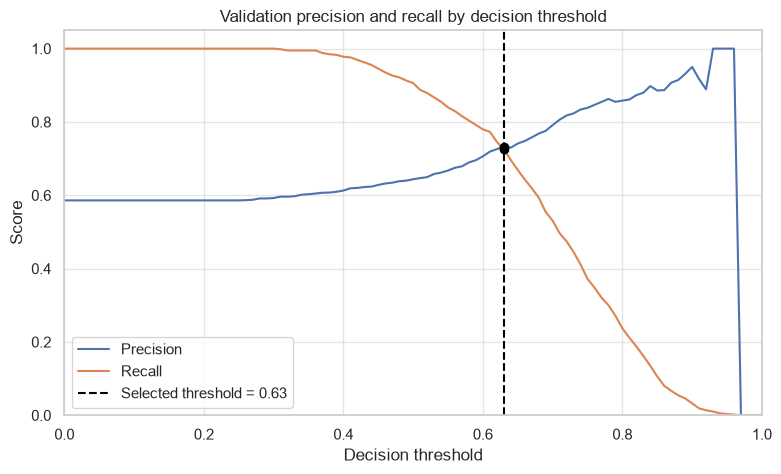

In [7]:
# Evaluate precision and recall at each validation decision threshold.
thresholds = np.linspace(0.0, 1.0, 101)
threshold_results = []

for threshold in thresholds:
    positive_predictions = y_pred >= threshold
    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(y_val, positive_predictions, zero_division=0),
        "recall": recall_score(y_val, positive_predictions, zero_division=0),
    })

threshold_metrics = pd.DataFrame(threshold_results)
valid_metrics = threshold_metrics.loc[
    (threshold_metrics["precision"] != 0) | (threshold_metrics["recall"] != 0)
].copy()
valid_metrics["abs_difference"] = (
    valid_metrics["precision"] - valid_metrics["recall"]
).abs()
intersection = valid_metrics.loc[valid_metrics["abs_difference"].idxmin()]

print(f"Intersection threshold: {intersection['threshold']:.2f}")
print(f"Precision: {intersection['precision']:.3f}")
print(f"Recall: {intersection['recall']:.3f}")
print(f"Absolute difference: {intersection['abs_difference']:.6f}")

# Plot both curves and mark the selected threshold.
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(threshold_metrics["threshold"], threshold_metrics["precision"], label="Precision")
ax.plot(threshold_metrics["threshold"], threshold_metrics["recall"], label="Recall")
ax.axvline(intersection["threshold"], color="black", linestyle="--",
           label=f"Selected threshold = {intersection['threshold']:.2f}")
ax.scatter([intersection["threshold"]] * 2,
           [intersection["precision"], intersection["recall"]],
           color="black", zorder=3)
ax.set(xlabel="Decision threshold", ylabel="Score",
       title="Validation precision and recall by decision threshold")
ax.set_xlim(0.0, 1.0)
ax.set_ylim(0.0, 1.05)
ax.legend()
plt.show()

<div style="padding: 14px 18px; border-left: 5px solid #16a34a; border-radius: 8px; background: #f0fdf4;">

**Result · Question 3 (precision and recall intersection)**

Across thresholds from `0.00` to `1.00` in steps of `0.01`, the closest sampled intersection occurs at **`0.63`**. At this threshold, precision is **`0.733`**, recall is **`0.725`**, and the absolute difference is **`0.007503`**. Thresholds where both metrics are zero were excluded.

**Selected option:** **`0.63`**
</div>

<div style="padding: 18px 22px; border-left: 6px solid #2563eb; border-radius: 8px; background: #eff6ff;">

## Step 6 · Question 4: F1-score maximization

**Objective.** Compute the harmonic mean ($F_1\text{-score}$) of precision and recall for all decision thresholds from `0.0` to `1.0` (step `0.01`), plot the curve, and determine the threshold that maximizes $F_1$.

</div>

Best F1 threshold: 0.41
Maximum F1 score: 0.758
Precision: 0.619
Recall: 0.976


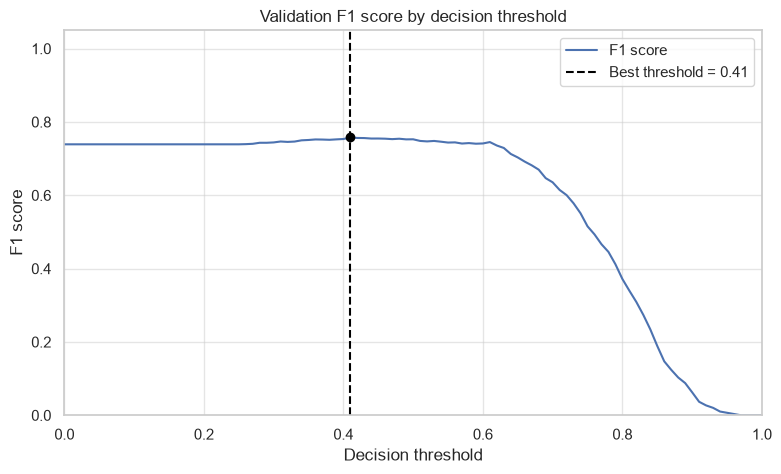

In [8]:
# Use the baseline model from Q2 to get validation probabilities for F1.
y_pred = model.predict_proba(X_val)[:, 1]
thresholds = np.linspace(0.0, 1.0, 101)
f1_values = [
    f1_score(y_val, y_pred >= threshold, zero_division=0)
    for threshold in thresholds
]
f1_by_threshold = pd.DataFrame({"threshold": thresholds, "f1": f1_values})

best_f1_row = f1_by_threshold.loc[f1_by_threshold["f1"].idxmax()]
best_positive_predictions = y_pred >= best_f1_row["threshold"]
best_precision = precision_score(y_val, best_positive_predictions, zero_division=0)
best_recall = recall_score(y_val, best_positive_predictions, zero_division=0)

print(f"Best F1 threshold: {best_f1_row['threshold']:.2f}")
print(f"Maximum F1 score: {best_f1_row['f1']:.3f}")
print(f"Precision: {best_precision:.3f}")
print(f"Recall: {best_recall:.3f}")

# Show the F1 curve and its maximum on the validation set.
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(f1_by_threshold["threshold"], f1_by_threshold["f1"], label="F1 score")
ax.axvline(best_f1_row["threshold"], color="black", linestyle="--",
           label=f"Best threshold = {best_f1_row['threshold']:.2f}")
ax.scatter(best_f1_row["threshold"], best_f1_row["f1"],
           color="black", zorder=3)
ax.set(xlabel="Decision threshold", ylabel="F1 score",
       title="Validation F1 score by decision threshold")
ax.set_xlim(0.0, 1.0)
ax.set_ylim(0.0, 1.05)
ax.legend()
plt.show()

<div style="padding: 14px 18px; border-left: 5px solid #16a34a; border-radius: 8px; background: #f0fdf4;">

**Result · Question 4 (maximum F1 score)**

The highest validation F1 score across the `0.01` threshold grid is **`0.758`** at threshold **`0.41`**. At that threshold, precision is **`0.619`** and recall is **`0.976`**. The calculation sets F1 to zero whenever precision and recall are both zero.

**Selected option:** **`0.41`**
</div>

<div style="padding: 18px 22px; border-left: 6px solid #2563eb; border-radius: 8px; background: #eff6ff;">

## Step 7 · Question 5: 5-Fold cross-validation stability

**Objective.** Evaluate the baseline model across 5 folds of `df_full_train` using `KFold(n_splits=5, shuffle=True, random_state=1)`, fitting the vectorizer and logistic regression strictly within each fold, and measure the standard deviation of validation ROC AUC scores across folds.

</div>

In [9]:
# Labels were saved separately before removing converted from df_full_train.
kf = KFold(n_splits=5, shuffle=True, random_state=1)
scores = []
cv_rows = []

for fold, (train_idx, val_idx) in enumerate(kf.split(df_full_train), start=1):
    # Select matching predictor rows and labels within the full training set.
    fold_train = df_full_train.iloc[train_idx]
    fold_val = df_full_train.iloc[val_idx]
    y_fold_train = y_full_train[train_idx]
    y_fold_val = y_full_train[val_idx]

    # Learn the feature mapping only from this fold's training observations.
    fold_dv = DictVectorizer(sparse=False)
    X_fold_train = fold_dv.fit_transform(fold_train.to_dict(orient="records"))
    X_fold_val = fold_dv.transform(fold_val.to_dict(orient="records"))

    fold_model = LogisticRegression(solver="liblinear", C=1.0, max_iter=1000)
    fold_model.fit(X_fold_train, y_fold_train)
    fold_probabilities = fold_model.predict_proba(X_fold_val)[:, 1]
    fold_auc = roc_auc_score(y_fold_val, fold_probabilities)

    scores.append(fold_auc)
    cv_rows.append({
        "fold": fold,
        "train_size": len(train_idx),
        "validation_size": len(val_idx),
        "roc_auc": fold_auc,
    })

cv_results = pd.DataFrame(cv_rows)
cv_auc_mean = np.mean(scores)
cv_auc_std = np.std(scores)  # Population standard deviation (ddof=0).
std_options = [0.001, 0.007, 0.013, 0.060]
q5_selected_option = min(std_options, key=lambda option: abs(option - cv_auc_std))

print(f"Full training observations: {len(df_full_train):,}")
print(cv_results.to_string(index=False, float_format=lambda value: f"{value:.6f}"))
print(f"Mean ROC AUC: {cv_auc_mean:.6f}")
print(f"ROC AUC standard deviation (ddof=0): {cv_auc_std:.6f}")
print(f"Closest answer option: {q5_selected_option:.3f}")

Full training observations: 4,000
 fold  train_size  validation_size  roc_auc
    1        3200              800 0.730560
    2        3200              800 0.729573
    3        3200              800 0.736343
    4        3200              800 0.741245
    5        3200              800 0.720914
Mean ROC AUC: 0.731727
ROC AUC standard deviation (ddof=0): 0.006853
Closest answer option: 0.007


<div style="padding: 14px 18px; border-left: 5px solid #16a34a; border-radius: 8px; background: #f0fdf4;">

**Result · Question 5 (5-Fold cross-validation stability)**

Across the five validation folds, the mean ROC AUC is **`0.731727`** and the standard deviation is **`0.006853`**, calculated with `np.std(scores)` (population standard deviation, `ddof=0`). The closest answer option is **`0.007`**.

Each fold uses **`3,200`** training observations and **`800`** validation observations from the **`4,000`** rows in `df_full_train`. A new vectorizer is fitted on each training fold, and a new logistic regression model is trained before scoring its validation fold.

**Selected option:** **`0.007`**
</div>

<div style="padding: 18px 22px; border-left: 6px solid #2563eb; border-radius: 8px; background: #eff6ff;">

## Step 8 · Question 6: Regularization parameter tuning with 5-Fold CV

**Objective.** Use 5-fold cross-validation across `C_values = [0.000001, 0.001, 1]` on `df_full_train` to identify the regularization strength achieving the highest mean ROC AUC, applying assignment tie-breaking rules if necessary.

</div>

In [10]:
# Compare regularization strengths on the same five full-training partitions.
C_values = [0.000001, 0.001, 1]
tuning_kf = KFold(n_splits=5, shuffle=True, random_state=1)
tuning_rows = []
tuning_fold_scores = {}

for C in C_values:
    c_scores = []

    for train_idx, val_idx in tuning_kf.split(df_full_train):
        fold_train = df_full_train.iloc[train_idx]
        fold_val = df_full_train.iloc[val_idx]
        y_fold_train = y_full_train[train_idx]
        y_fold_val = y_full_train[val_idx]

        # Fit a new vectorizer and model within each training fold.
        tuning_dv = DictVectorizer(sparse=False)
        X_fold_train = tuning_dv.fit_transform(fold_train.to_dict(orient="records"))
        X_fold_val = tuning_dv.transform(fold_val.to_dict(orient="records"))

        tuning_model = LogisticRegression(solver="liblinear", C=C, max_iter=1000)
        tuning_model.fit(X_fold_train, y_fold_train)
        tuning_probabilities = tuning_model.predict_proba(X_fold_val)[:, 1]
        c_scores.append(roc_auc_score(y_fold_val, tuning_probabilities))

    # Preserve full precision until the assignment's final rounding step.
    tuning_fold_scores[C] = c_scores
    tuning_rows.append({
        "C": C,
        "mean_auc": np.mean(c_scores),
        "std_auc": np.std(c_scores),
    })

tuning_results_raw = pd.DataFrame(tuning_rows)
tuning_results = tuning_results_raw.copy()
for metric in ["mean_auc", "std_auc"]:
    tuning_results[metric] = tuning_results_raw[metric].map(lambda value: round(value, 3))

# Compare the reported scores: highest mean, lowest std, then smallest C.
tuning_ranked = tuning_results.sort_values(
    by=["mean_auc", "std_auc", "C"],
    ascending=[False, True, True],
)
best_C = tuning_ranked.iloc[0]["C"]

print(tuning_results.to_string(index=False, formatters={
    "C": lambda value: f"{value:.6g}",
    "mean_auc": lambda value: f"{value:.3f}",
    "std_auc": lambda value: f"{value:.3f}",
}))
print(f"Selected C: {best_C:g}")

    C mean_auc std_auc
1e-06    0.617   0.019
0.001    0.749   0.010
    1    0.732   0.007
Selected C: 0.001


<div style="padding: 14px 18px; border-left: 5px solid #16a34a; border-radius: 8px; background: #f0fdf4;">

**Result · Question 6 (regularization tuning)**

| C | Mean ROC AUC | ROC AUC standard deviation |
| :--- | ---: | ---: |
| 0.000001 | 0.617 | 0.019 |
| 0.001 | **0.749** | 0.010 |
| 1 | 0.732 | 0.007 |

The selected value is **`C=0.001`**, which achieves the highest mean validation ROC AUC across the five folds. Metrics are rounded to three decimals as required, and the standard deviation uses `np.std` with `ddof=0`. The means are distinct, so no tie-break is needed. The selection code orders the reported results by descending mean ROC AUC, ascending standard deviation, and ascending `C`.

All three candidates use the same `KFold(n_splits=5, shuffle=True, random_state=1)` partitions of `df_full_train`, with a vectorizer fitted separately within each training fold.

**Selected option:** **`0.001`**
</div>

<div style="padding: 18px 22px; border-left: 6px solid #2563eb; border-radius: 8px; background: #eff6ff;">

## Step 9 · Results dashboard and final takeaways

**Objective.** Consolidate all computed evaluation metrics, selected options, and methodological takeaways into an executive dashboard.

**Dashboard contents.** Review the six selected answers, their supporting metrics and evaluation splits, the baseline threshold curves, and the cross-validation comparison of regularization strengths. The executable summary reads the results computed in Steps 3–8.

</div>

<div style="padding: 22px 26px; border: 1px solid #bfdbfe; border-top: 7px solid #2563eb; border-radius: 12px; background: #f8fafc;">

## Homework 4 · Results dashboard

| Question | Focus | Calculated metric / value | Selected option | Brief justification |
| :---: | :--- | :--- | :---: | :--- |
| **Q1** | Univariate feature ROC AUC | Training AUC: `0.788` | **`lead_score`** | Highest individual ranking ability among the four numerical features evaluated. |
| **Q2** | Baseline validation ROC AUC | Validation AUC: `0.732` | **`0.732`** | Logistic regression with `C=1`, using a vectorizer fitted on training data. |
| **Q3** | Precision and recall intersection | Threshold: `0.63`; precision: `0.733`; recall: `0.725` | **`0.63`** | Smallest nondegenerate precision–recall gap on the `0.01` threshold grid: `0.007503`. |
| **Q4** | Maximum validation F1 | Threshold: `0.41`; F1: `0.758`; precision: `0.619`; recall: `0.976` | **`0.41`** | Highest F1 on the same threshold grid for the baseline model. |
| **Q5** | Baseline 5-fold CV stability | Mean AUC: `0.731727`; standard deviation: `0.006853` | **`0.007`** | Population standard deviation across the five validation folds (`ddof=0`). |
| **Q6** | Regularization tuning | Best mean AUC: `0.749`; standard deviation: `0.010` | **`C=0.001`** | Highest mean AUC among the three candidates; no tie-break was needed. |

</div>

<div style="margin-top: 16px; padding: 16px 20px; border-left: 5px solid #f59e0b; border-radius: 8px; background: #fffbeb;">

### Final takeaways

- **Feature ranking.** `lead_score` is the strongest individual numerical feature on the training split. Its univariate training AUC is measured on a different sample from the model's validation AUC, so the two values do not establish which approach generalizes better.
- **Threshold choice depends on the objective.** At `0.63`, baseline precision and recall are close. At `0.41`, baseline F1 is highest, with much higher recall and lower precision. These thresholds describe the baseline model (`C=1`); the tuned model needs its own threshold evaluation.
- **Regularization improves mean CV performance.** `C=0.001` achieves mean AUC `0.749`, versus `0.732` for `C=1` and `0.617` for `C=0.000001`. Smaller `C` means stronger regularization; `C=1` is also regularized.
- **Performance and dispersion answer different questions.** The selected model has higher mean AUC and higher fold dispersion (`0.010`) than the baseline (`0.007`). Selection follows the prescribed mean-AUC criterion. These standard deviations describe variation across the five folds; they are not confidence intervals.

</div>

### Evaluation scope and reproducibility

The 5,000 observations are split into 3,000 training, 1,000 validation, and 1,000 test rows. Q1 uses the training split; Q2–Q4 use the validation split. Q5–Q6 use the 4,000-row full training set, with 3,200 training and 800 validation observations per fold.

Missing predictors are filled with the prescribed fixed values (`"NA"` for categoricals and `0.0` for numericals). Each vectorizer is fitted on its training partition, then applied to its validation partition. CV uses `KFold(n_splits=5, shuffle=True, random_state=1)` for every candidate. Final Q6 metrics are rounded to three decimals, with ties resolved by lower standard deviation and then lower `C`.

The results below summarize training and validation evidence. A final test-set evaluation of the selected model has not been performed.

,Selected option,Computed evidence,Evaluation scope
Question,,,
Q1,lead_score,Best feature ROC AUC = 0.788,Training split
Q2,0.732,Baseline ROC AUC = 0.732,Validation split
Q3,0.63,Precision = 0.733; recall = 0.725; gap = 0.007503,Validation split; C=1
Q4,0.41,F1 = 0.758; precision = 0.619; recall = 0.976,Validation split; C=1
Q5,0.007,Mean AUC = 0.731727; std = 0.006853,Full train; 5-fold CV; C=1
Q6,C=0.001,Mean AUC = 0.749; std = 0.010,Full train; 5-fold CV


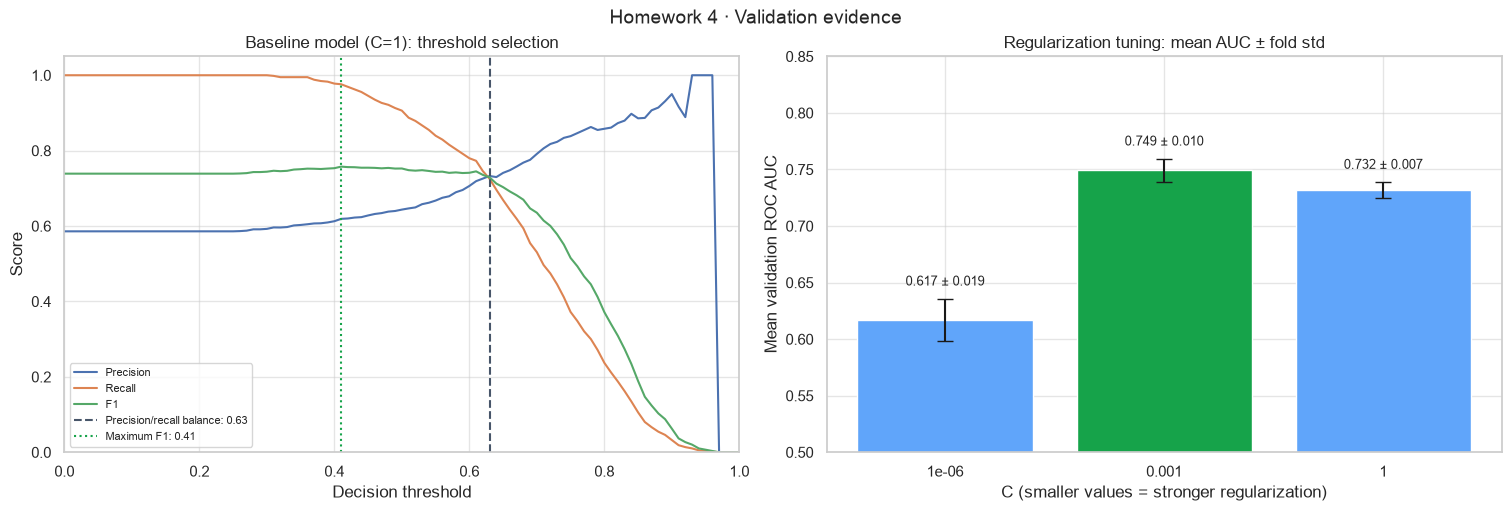

Selected C: 0.001
Mean CV ROC AUC improvement over the baseline: 0.017
Error bars show fold standard deviations (ddof=0), not confidence intervals.
Threshold results apply to the baseline C=1 model; final test evaluation is pending.


In [11]:
# Build the summary from the computed results of Q1-Q6.
selected_cv = tuning_results_raw.loc[tuning_results_raw["C"].eq(best_C)].iloc[0]
dashboard_rows = [
    ("Q1", best_feature,
     f"Best feature ROC AUC = {auc_by_feature[best_feature]:.3f}", "Training split"),
    ("Q2", f"{auc_val:.3f}",
     f"Baseline ROC AUC = {auc_val:.3f}", "Validation split"),
    ("Q3", f"{intersection['threshold']:.2f}",
     f"Precision = {intersection['precision']:.3f}; recall = {intersection['recall']:.3f}; "
     f"gap = {intersection['abs_difference']:.6f}", "Validation split; C=1"),
    ("Q4", f"{best_f1_row['threshold']:.2f}",
     f"F1 = {best_f1_row['f1']:.3f}; precision = {best_precision:.3f}; "
     f"recall = {best_recall:.3f}", "Validation split; C=1"),
    ("Q5", f"{q5_selected_option:.3f}",
     f"Mean AUC = {cv_auc_mean:.6f}; std = {cv_auc_std:.6f}", "Full train; 5-fold CV; C=1"),
    ("Q6", f"C={best_C:g}",
     f"Mean AUC = {selected_cv['mean_auc']:.3f}; std = {selected_cv['std_auc']:.3f}",
     "Full train; 5-fold CV"),
]
results_dashboard = pd.DataFrame(
    dashboard_rows,
    columns=["Question", "Selected option", "Computed evidence", "Evaluation scope"],
)
display(results_dashboard.set_index("Question"))

# Summarize the baseline threshold trade-off and the CV model comparison.
fig, axes = plt.subplots(1, 2, figsize=(15, 5), constrained_layout=True)

axes[0].plot(threshold_metrics["threshold"], threshold_metrics["precision"], label="Precision")
axes[0].plot(threshold_metrics["threshold"], threshold_metrics["recall"], label="Recall")
axes[0].plot(f1_by_threshold["threshold"], f1_by_threshold["f1"], label="F1")
axes[0].axvline(intersection["threshold"], color="#475569", linestyle="--",
               label=f"Precision/recall balance: {intersection['threshold']:.2f}")
axes[0].axvline(best_f1_row["threshold"], color="#16a34a", linestyle=":",
               label=f"Maximum F1: {best_f1_row['threshold']:.2f}")
axes[0].set(xlabel="Decision threshold", ylabel="Score", xlim=(0, 1), ylim=(0, 1.05),
            title="Baseline model (C=1): threshold selection")
axes[0].legend(fontsize=8)

positions = np.arange(len(tuning_results_raw))
colors = ["#16a34a" if C == best_C else "#60a5fa" for C in tuning_results_raw["C"]]
axes[1].bar(positions, tuning_results_raw["mean_auc"],
            yerr=tuning_results_raw["std_auc"], capsize=6, color=colors)
axes[1].set_xticks(positions)
axes[1].set_xticklabels([f"{C:.6g}" for C in tuning_results_raw["C"]])
for position, row in zip(positions, tuning_results_raw.itertuples(index=False)):
    axes[1].text(position, row.mean_auc + row.std_auc + 0.012,
                 f"{row.mean_auc:.3f} ± {row.std_auc:.3f}", ha="center", fontsize=9)
axes[1].set(xlabel="C (smaller values = stronger regularization)",
            ylabel="Mean validation ROC AUC", ylim=(0.5, 0.85),
            title="Regularization tuning: mean AUC ± fold std")
fig.suptitle("Homework 4 · Validation evidence", fontsize=14)
plt.show()

cv_auc_gain = selected_cv["mean_auc"] - cv_auc_mean
print(f"Selected C: {best_C:g}")
print(f"Mean CV ROC AUC improvement over the baseline: {cv_auc_gain:.3f}")
print("Error bars show fold standard deviations (ddof=0), not confidence intervals.")
print("Threshold results apply to the baseline C=1 model; final test evaluation is pending.")